<a href="https://colab.research.google.com/github/dipalimhapsekar/CSL701-CE-28_Machine-Learning-Lab/blob/main/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Dipali Manohar Mhapsekar CE28


### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
dfp = pd.read_csv('/content/palmerpenguins_extended.csv')
display(dfp.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [32]:
# Check for missing values
print("Missing values before preprocessing:\n", dfp.isnull().sum())

# Drop rows with missing values
dfp = dfp.dropna()

# Select Features and Target
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Use correct columns if named slightly differently in the dataset
# Map columns to correspond with standard names in the prompt
rename_dict = {
    'culmen_length_mm': 'bill_length_mm',
    'culmen_depth_mm': 'bill_depth_mm'
}
dfp = dfp.rename(columns=rename_dict)

# Filter features to those that actually exist
existing_features = [f for f in features if f in dfp.columns]
if len(existing_features) < 4:
    # Fallback to check other potential names
    alternatives = {'culmen_length_mm': 'bill_length_mm', 'culmen_depth_mm': 'bill_depth_mm'}
    for alt, standard in alternatives.items():
        if alt in dfp.columns and standard not in dfp.columns:
            dfp[standard] = dfp[alt]
            existing_features.append(standard)

X = dfp[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = dfp['species']

# Encode categorical targets
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("\nEncoded classes:", dict(zip(le.classes_, le.transform(le.classes_))))

Missing values before preprocessing:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Encoded classes: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [34]:
# Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (266, 4)
Testing set shape: (67, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [35]:
# Initialize and train CART model using Gini impurity
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_model.fit(X_train, y_train)
# Predict on test set
y_pred_cart = cart_model.predict(X_test)


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Classifier Accuracy: 0.9403

Confusion Matrix:


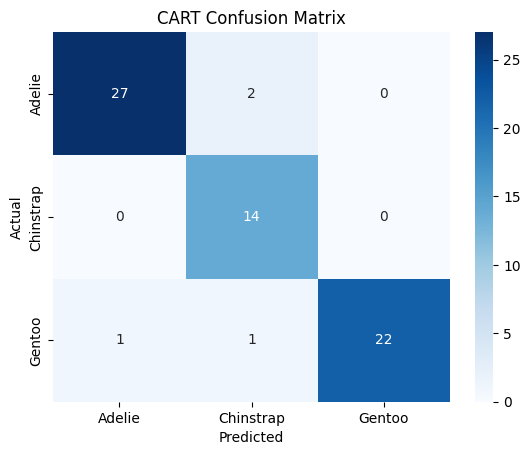


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.96      0.93      0.95        29
   Chinstrap       0.82      1.00      0.90        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.94        67
   macro avg       0.93      0.95      0.94        67
weighted avg       0.95      0.94      0.94        67



In [37]:
# Calculate performance metrics for CART model
cart_acc = accuracy_score(y_test, y_pred_cart)
print(f"CART Classifier Accuracy: {cart_acc:.4f}\n")

print("Confusion Matrix:")
cm_cart = confusion_matrix(y_test, y_pred_cart)
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CART Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


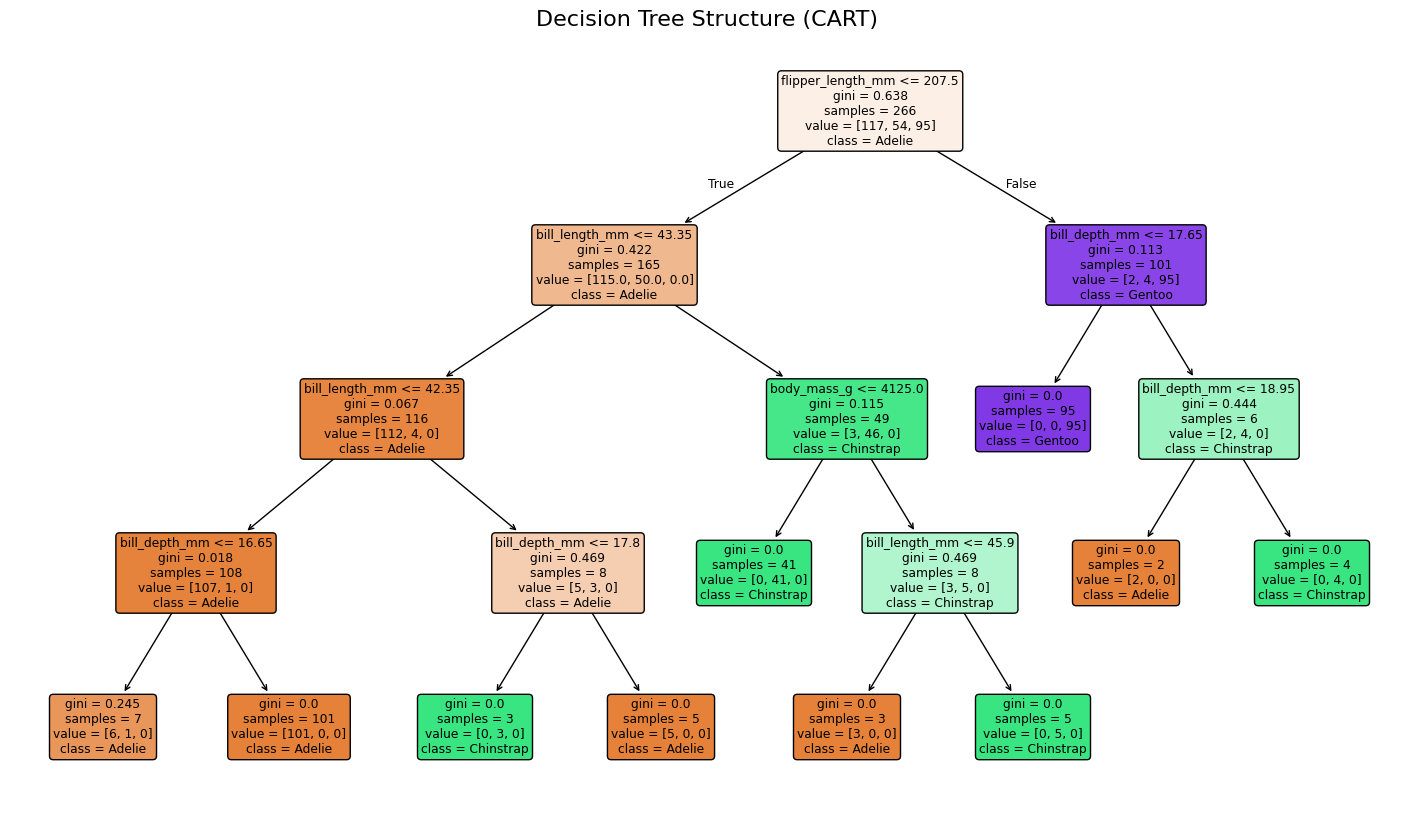

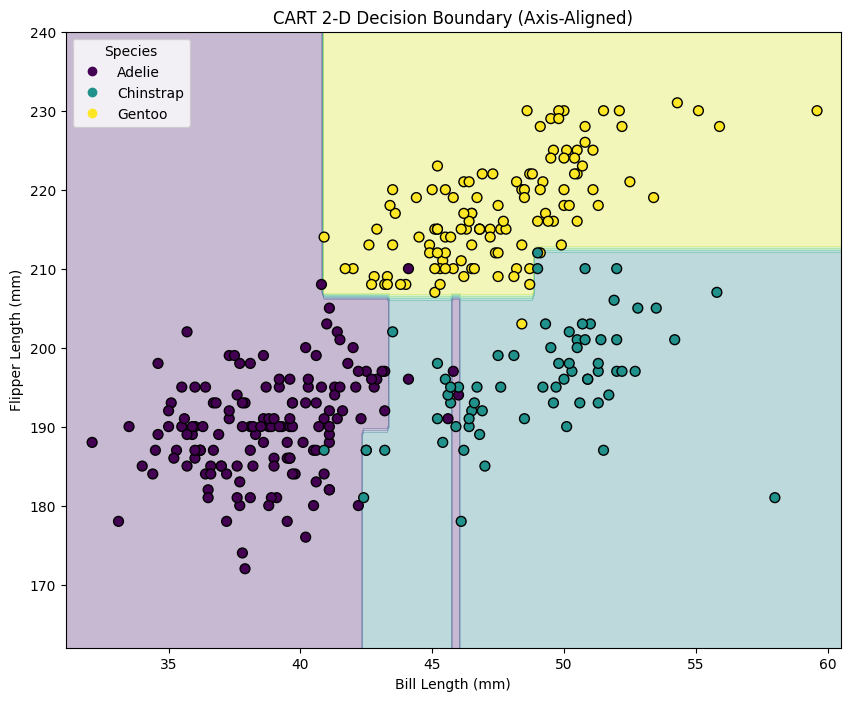

In [39]:
# 1. Visualize the Tree Structure
plt.figure(figsize=(18, 10))
plot_tree(cart_model, feature_names=features, class_names=le.classes_, filled=True, rounded=True)
plt.title("Decision Tree Structure (CART)", fontsize=16)
plt.show()

# 2. Select 2-D Features for visualization
# We will use 'bill_length_mm' and 'flipper_length_mm'
X_2d = dfp[['bill_length_mm', 'flipper_length_mm']].values
y_2d = y_encoded

# Train 2-D Model
cart_2d = DecisionTreeClassifier(max_depth=4, random_state=42)
cart_2d.fit(X_2d, y_2d)

# 3. Plot Decision Boundary
# Create a mesh grid to predict over
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 10, X_2d[:, 1].max() + 10
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 1))

# Predict for each point on the grid
Z = cart_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundaries
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

# Scatter plot of dataset points
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, edgecolor='k', cmap='viridis', s=50)
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('CART 2-D Decision Boundary (Axis-Aligned)')
handles, _ = scatter.legend_elements()
plt.legend(handles, le.classes_, title="Species")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

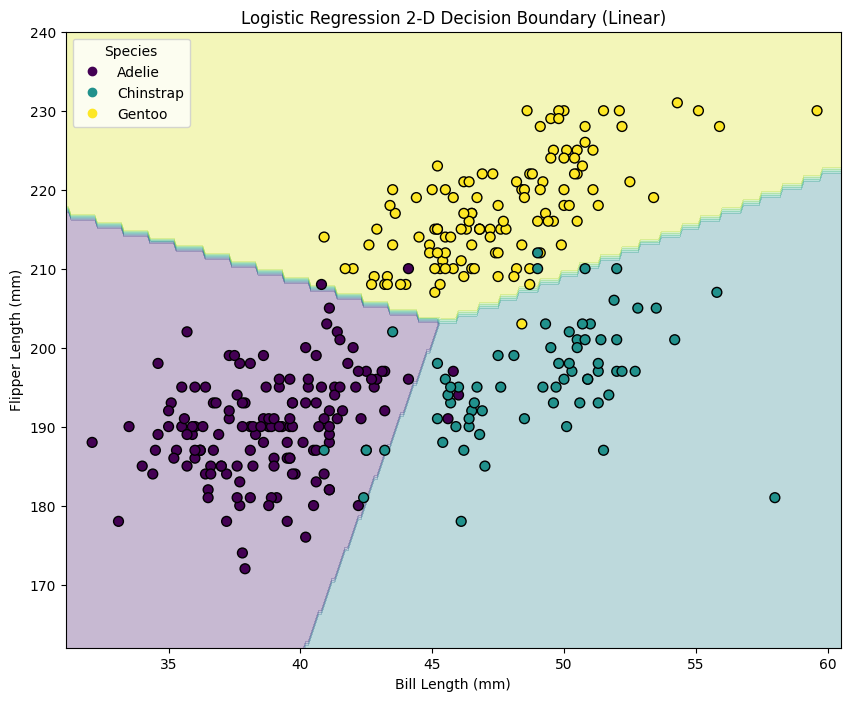

In [41]:
# Train a Logistic Regression model on the same 2-D features
log_reg_2d = LogisticRegression(random_state=42)
log_reg_2d.fit(X_2d, y_2d)

# Predict for each point on the same grid we constructed in Task 6
Z_lr = log_reg_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_lr = Z_lr.reshape(xx.shape)

# Plot the linear decision boundaries of Logistic Regression
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z_lr, alpha=0.3, cmap='viridis')

# Scatter plot of dataset points
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, edgecolor='k', cmap='viridis', s=50)
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('Logistic Regression 2-D Decision Boundary (Linear)')
handles, _ = scatter.legend_elements()
plt.legend(handles, le.classes_, title="Species")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

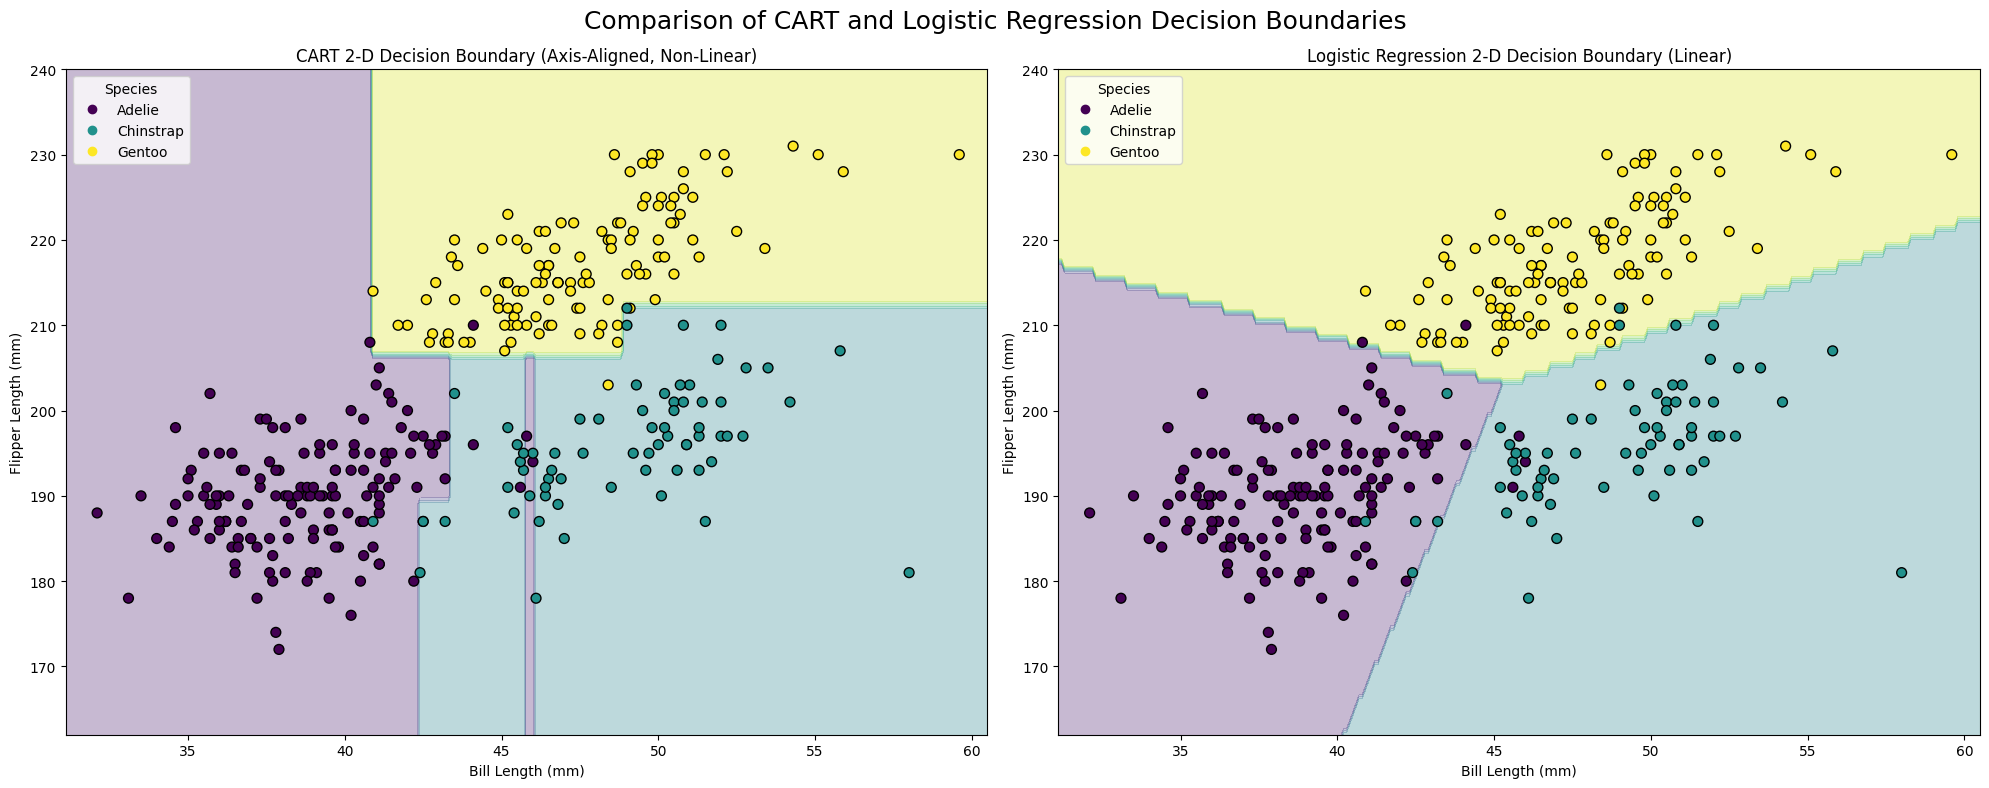

In [43]:
# Create side-by-side subplots for comparison
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. Plot CART Decision Boundary
axes[0].contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
scatter1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, edgecolor='k', cmap='viridis', s=50)
axes[0].set_xlabel('Bill Length (mm)')
axes[0].set_ylabel('Flipper Length (mm)')
axes[0].set_title('CART 2-D Decision Boundary (Axis-Aligned, Non-Linear)')
handles1, _ = scatter1.legend_elements()
axes[0].legend(handles1, le.classes_, title="Species")

# 2. Plot Logistic Regression Decision Boundary
axes[1].contourf(xx, yy, Z_lr, alpha=0.3, cmap='viridis')
scatter2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, edgecolor='k', cmap='viridis', s=50)
axes[1].set_xlabel('Bill Length (mm)')
axes[1].set_ylabel('Flipper Length (mm)')
axes[1].set_title('Logistic Regression 2-D Decision Boundary (Linear)')
handles2, _ = scatter2.legend_elements()
axes[1].legend(handles2, le.classes_, title="Species")

plt.suptitle('Comparison of CART and Logistic Regression Decision Boundaries', fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


=== Performance Comparison ===

CART Decision Tree Accuracy : 0.9403
Logistic Regression Accuracy: 0.9851

=== CART Classification Report ===
              precision    recall  f1-score   support

      Adelie       0.96      0.93      0.95        29
   Chinstrap       0.82      1.00      0.90        14
      Gentoo       1.00      0.92      0.96        24

    accuracy                           0.94        67
   macro avg       0.93      0.95      0.94        67
weighted avg       0.95      0.94      0.94        67

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        29
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       0.96      1.00      0.98        24

    accuracy                           0.99        67
   macro avg       0.99      0.99      0.99        67
weighted avg       0.99      0.99      0.99        67



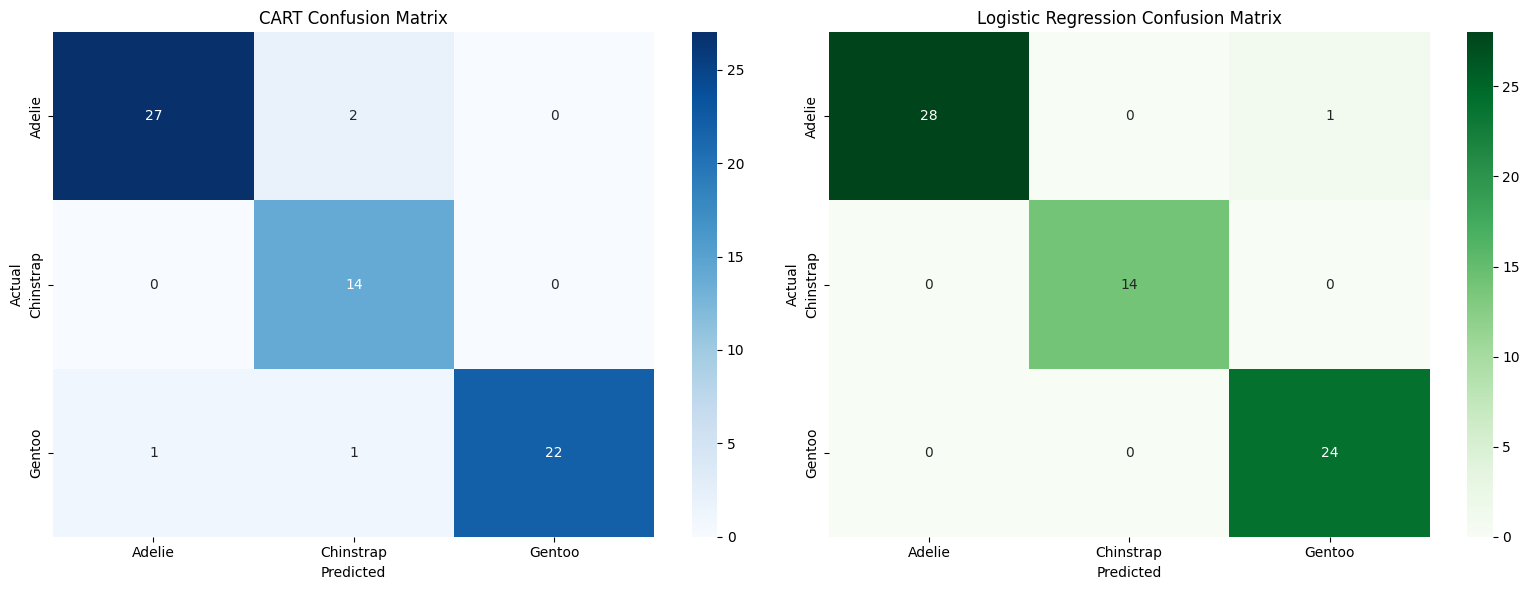

In [44]:
# Evaluate the performance of Logistic Regression on the test set
# Let's train Logistic Regression on full features first to make a fair comparison
log_reg_full = LogisticRegression(max_iter=1000, random_state=42)
log_reg_full.fit(X_train, y_train)
y_pred_lr = log_reg_full.predict(X_test)

lr_acc = accuracy_score(y_test, y_pred_lr)

print("=== Performance Comparison ===\n")
print(f"CART Decision Tree Accuracy : {cart_acc:.4f}")
print(f"Logistic Regression Accuracy: {lr_acc:.4f}\n")

print("=== CART Classification Report ===")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

print("=== Logistic Regression Classification Report ===")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

# Plot confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title('CART Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.